In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Fashion MNIST veri setinin yüklenmesi
fashion_mnist = keras.datasets.fashion_mnist
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

# Sınıf isimlerinin tanımlanması
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Yoğunluk değerlerini normalize ediyoruz ve doğrulama setini ayırıyoruz
X_valid, X_train = X_train_full[:6000] / 255.0, X_train_full[6000:] / 255.0
y_valid, y_train = y_train_full[:6000], y_train_full[6000:]
X_test = X_test / 255.0

print(f"Eğitim seti boyutu: {X_train.shape}")
print(f"Doğrulama seti boyutu: {X_valid.shape}")
print(f"Test seti boyutu: {X_test.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Eğitim seti boyutu: (54000, 28, 28)
Doğrulama seti boyutu: (6000, 28, 28)
Test seti boyutu: (10000, 28, 28)


### 1. Kütüphanelerin Yüklenmesi ve Veri Setinin Hazırlanması

Bu adımda projemizde kullanacağımız temel kütüphaneleri içe aktarıyor ve Fashion MNIST veri setini TensorFlow/Keras aracılığıyla yüklüyoruz.

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# Fashion MNIST veri setinin yüklenmesi
fashion_mnist = keras.datasets.fashion_mnist
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

# Sınıf isimlerinin tanımlanması
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

### 2. Verilerin Ön İşlenmesi (Preprocessing) ve Ölçeklendirme

Piksel değerlerini $[0, 1]$ aralığına normalize ediyor ve eğitim verisinden bir doğrulama (validation) seti ayırıyoruz.

In [ ]:
# Yoğunluk değerlerini 255.0'e bölerek normalize ediyoruz
# Aynı zamanda eğitim verisinden ilk 5000 örneği doğrulama seti (validation set) olarak ayırıyoruz
X_valid, X_train = X_train_full[:6000] / 255.0, X_train_full[6000:] / 255.0
y_valid, y_train = y_train_full[:6000], y_train_full[6000:]
X_test = X_test / 255.0

print(f"Eğitim seti boyutu: {X_train.shape}")
print(f"Doğrulama seti boyutu: {X_valid.shape}")
print(f"Test seti boyutu: {X_test.shape}")

Eğitim seti boyutu: (54000, 28, 28)
Doğrulama seti boyutu: (6000, 28, 28)
Test seti boyutu: (10000, 28, 28)


### 3. Yapay Sinir Ağı Modelinin Oluşturulması ve Derlenmesi

Bu adımda, girdi katmanı (düzleştirme), iki gizli katman (ReLU aktivasyon fonksiyonlu) ve çıktı katmanından (Softmax aktivasyon fonksiyonlu) oluşan bir Çok Katmanlı Algılayıcı (MLP) modeli tanımlıyoruz.

In [ ]:
import tensorflow as tf
from tensorflow import keras

model = keras.models.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

model.summary()

# Modelin Derlenmesi
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="sgd",
              metrics=["accuracy"])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 300)            │       235,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        30,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

### 4. Modelin Eğitilmesi

Modeli öncelikle 10 epoch boyunca eğitiyoruz ve eğitim geçmişini (history) kaydediyoruz.

In [ ]:
history = model.fit(X_train, y_train, epochs=10,
                    validation_data=(X_valid, y_valid))

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7628 - loss: 0.7254 - val_accuracy: 0.7833 - val_loss: 0.6112
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8305 - loss: 0.4898 - val_accuracy: 0.8443 - val_loss: 0.4631
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8455 - loss: 0.4439 - val_accuracy: 0.8577 - val_loss: 0.4204
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8520 - loss: 0.4183 - val_accuracy: 0.8567 - val_loss: 0.4107
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8613 - loss: 0.3964 - val_accuracy: 0.8503 - val_loss: 0.4265
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8663 - loss: 0.3806 - val_accuracy: 0.8627 - val_loss: 0.3927
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8704 - loss: 0.3678 - val_accuracy: 0.8665 - val_loss: 0.3771
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - accuracy: 0.8746 - loss: 0.3551 -

### 5. Eğitim ve Doğrulama Grafikleri (Loss ve Accuracy)

Eğitim sürecindeki kayıp (loss) ve doğruluk (accuracy) değerlerini görselleştiriyoruz.

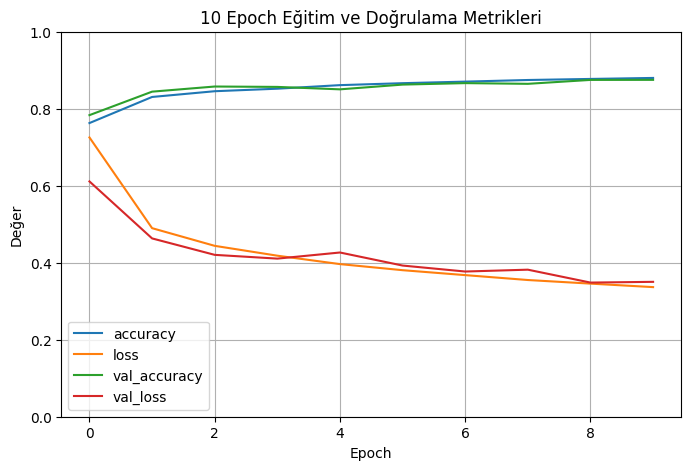

In [ ]:
import pandas as pd

pd.DataFrame(history.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.title("10 Epoch Eğitim ve Doğrulama Metrikleri")
plt.xlabel("Epoch")
plt.ylabel("Değer")
plt.show()

### 6. Modelin Test Verileri Üzerinde Değerlendirilmesi ve Tahminlerin Görselleştirilmesi

313/313 - 1s - 3ms/step - accuracy: 0.8638 - loss: 0.3816

Test Doğruluğu (10 Epoch): 0.8638
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


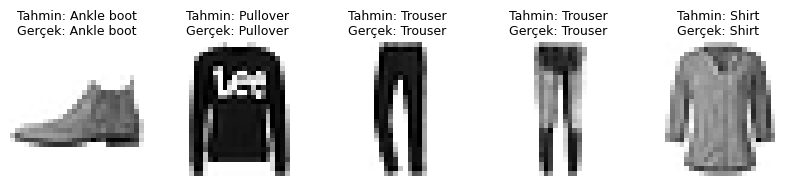

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nTest Doğruluğu (10 Epoch): {test_acc:.4f}")

# İlk 5 test örneği için tahminler
X_new = X_test[:5]
y_proba = model.predict(X_new)
y_pred = np.argmax(y_proba, axis=-1)

plt.figure(figsize=(10, 3))
for index, image in enumerate(X_new):
    plt.subplot(1, 5, index + 1)
    plt.imshow(image, cmap="binary")
    plt.axis('off')
    plt.title(f"Tahmin: {class_names[y_pred[index]]}\nGerçek: {class_names[y_test[index]]}", fontsize=9)
plt.show()

### 7. Farklı Epoch Sayısı (Örn: 20 Epoch) ile Yeniden Eğitim ve Karşılaştırma

Epoch 1/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7624 - loss: 0.7368 - val_accuracy: 0.7423 - val_loss: 0.6523
Epoch 2/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8281 - loss: 0.4922 - val_accuracy: 0.8360 - val_loss: 0.4679
Epoch 3/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8457 - loss: 0.4452 - val_accuracy: 0.8508 - val_loss: 0.4380
Epoch 4/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8548 - loss: 0.4177 - val_accuracy: 0.8552 - val_loss: 0.4219
Epoch 5/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8606 - loss: 0.3974 - val_accuracy: 0.8618 - val_loss: 0.4067
Epoch 6/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8671 - loss: 0.3822 - val_accuracy: 0.8635 - val_loss: 0.3874
Epoch 7/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8708 - loss: 0.3684 - val_accuracy: 0.8708 - val_loss: 0.3723
Epoch 8/20
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8755 - loss: 0.3573 

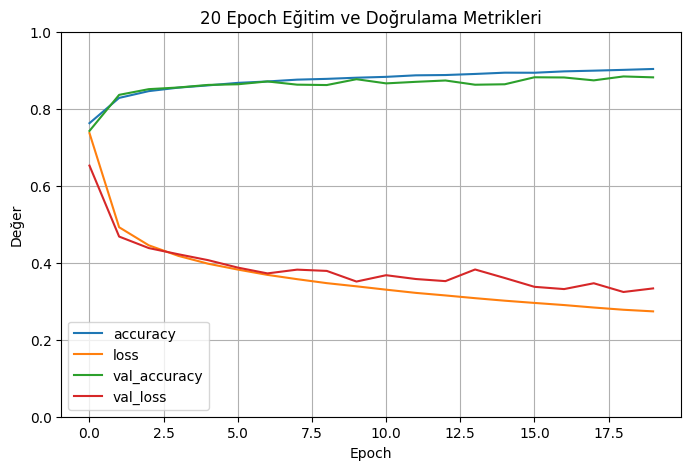

313/313 - 1s - 3ms/step - accuracy: 0.8726 - loss: 0.3642

20 Epoch Test Doğruluğu: 0.8726


In [ ]:
import pandas as pd

# Yeni bir model nesnesi oluşturup sıfırdan derliyoruz
model_20 = keras.models.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

model_20.compile(loss="sparse_categorical_crossentropy",
                 optimizer="sgd",
                 metrics=["accuracy"])

# 20 Epoch boyunca eğitim
history_20 = model_20.fit(X_train, y_train, epochs=20,
                          validation_data=(X_valid, y_valid))

# Grafik
pd.DataFrame(history_20.history).plot(figsize=(8, 5))
plt.grid(True)
plt.gca().set_ylim(0, 1)
plt.title("20 Epoch Eğitim ve Doğrulama Metrikleri")
plt.xlabel("Epoch")
plt.ylabel("Değer")
plt.show()

# Test Değerlendirmesi
test_loss_20, test_acc_20 = model_20.evaluate(X_test, y_test, verbose=2)
print(f"\n20 Epoch Test Doğruluğu: {test_acc_20:.4f}")

### 8. Gelişmiş Model Deneyi: 30 Epoch, Erken Durdurma (Early Stopping) ve En İyi Modeli Kaydetme

Gerçek projelerde epoch sayısını doğrudan artırmak aşırı öğrenmeye (overfitting) neden olabilir. Bunu engellemek ve en iyi performans gösteren modeli elde etmek için `EarlyStopping` ve `ModelCheckpoint` callbacks yapılarını kullanıyoruz.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Yeni bir gelişmiş model yapısı (Keras 3 uyumlu)
model_advanced = keras.models.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),
    keras.layers.Dense(300, activation="relu"),
    keras.layers.Dense(100, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

model_advanced.compile(loss="sparse_categorical_crossentropy",
                       optimizer="adam", # Daha hızlı yakınsama için Adam optimizer
                       metrics=["accuracy"])

# En iyi modeli kaydetmek ve aşırı öğrenmeyi önlemek için Callback tanımları
callbacks = [
    EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss'),
    ModelCheckpoint("best_fashion_mnist_model.keras", save_best_only=True, monitor='val_loss')
]

# 30 Epoch eğitim
history_advanced = model_advanced.fit(X_train, y_train, epochs=30,
                                      validation_data=(X_valid, y_valid),
                                      callbacks=callbacks)

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.8261 - loss: 0.4841 - val_accuracy: 0.8550 - val_loss: 0.3920
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8661 - loss: 0.3634 - val_accuracy: 0.8783 - val_loss: 0.3394
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8788 - loss: 0.3273 - val_accuracy: 0.8892 - val_loss: 0.3128
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 7ms/step - accuracy: 0.8874 - loss: 0.3054 - val_accuracy: 0.8723 - val_loss: 0.3563
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.8926 - loss: 0.2857 - val_accuracy: 0.8870 - val_loss: 0.3128
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8995 - loss: 0.2697 - val_accuracy: 0.8920 - val_loss: 0.3027
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9025 - loss: 0.2592 - val_accuracy: 0.8813 - val_loss: 0.3282
Epoch 8/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9084 - loss: 0

### 9. Profesyonel Performans Analizi: Karmaşıklık Matrisi ve Sınıflandırma Raporu

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

--- Detaylı Sınıflandırma Raporu ---
              precision    recall  f1-score   support

 T-shirt/top       0.87      0.80      0.83      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.85      0.71      0.78      1000
       Dress       0.88      0.90      0.89      1000
        Coat       0.79      0.81      0.80      1000
      Sandal       0.96      0.97      0.96      1000
       Shirt       0.64      0.78      0.70      1000
     Sneaker       0.92      0.96      0.94      1000
         Bag       0.98      0.96      0.97      1000
  Ankle boot       0.97      0.92      0.94      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



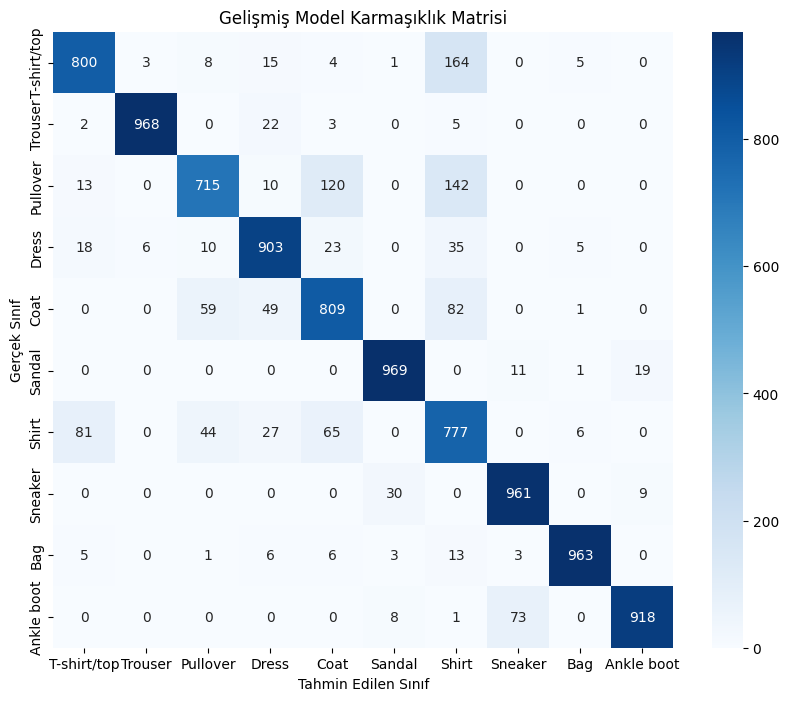

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# Test seti tahminleri
y_pred_advanced = np.argmax(model_advanced.predict(X_test), axis=-1)

# Sınıflandırma Raporu
print("\n--- Detaylı Sınıflandırma Raporu ---")
print(classification_report(y_test, y_pred_advanced, target_names=class_names))

# Karmaşıklık Matrisi (Confusion Matrix) Görselleştirme
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred_advanced)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Gelişmiş Model Karmaşıklık Matrisi")
plt.ylabel('Gerçek Sınıf')
plt.xlabel('Tahmin Edilen Sınıf')
plt.show()

### 10. Hatalı Tahminlerin Analizi

Modelin yaptığı hataları incelemek, modelimizi geliştirmek için en önemli adımdır. Aşağıda modelin yanlış sınıflandırdığı bazı örnekleri görselleştiriyoruz.

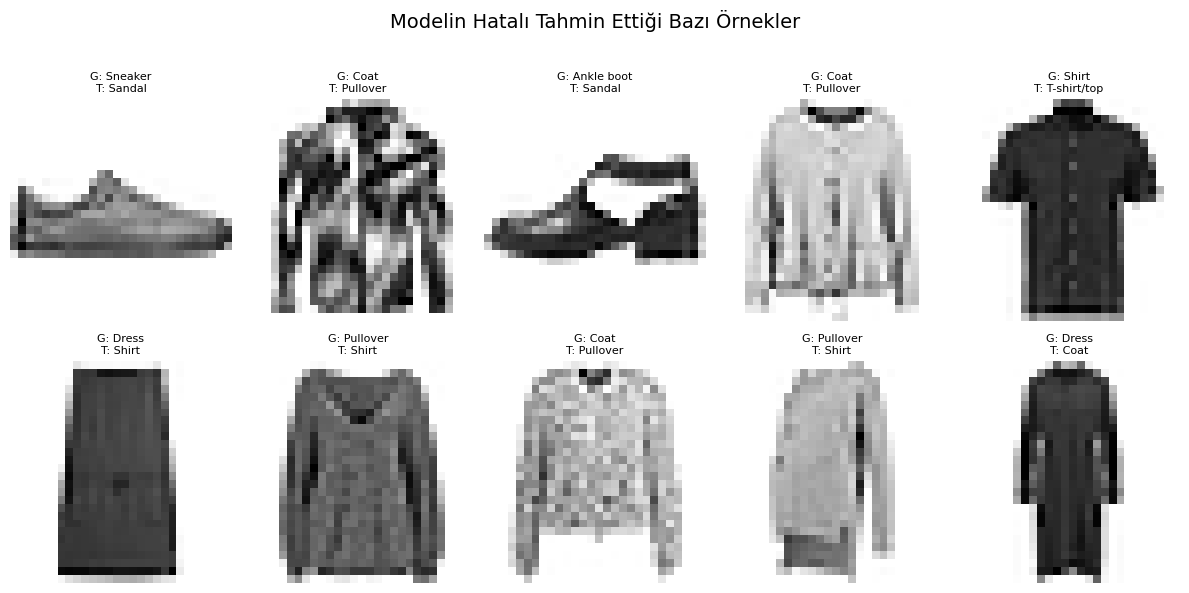

In [ ]:
incorrect_indices = np.where(y_pred_advanced != y_test)[0]

plt.figure(figsize=(12, 6))
for i, incorrect in enumerate(incorrect_indices[:10]):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[incorrect], cmap="binary")
    plt.axis('off')
    plt.title(f"G: {class_names[y_test[incorrect]]}\nT: {class_names[y_pred_advanced[incorrect]]}", fontsize=8)
plt.suptitle("Modelin Hatalı Tahmin Ettiği Bazı Örnekler", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
import tensorflow as tf
from tensorflow import keras

# En gelişmiş mimari tasarımı
model_pro = keras.models.Sequential([
    keras.layers.Input(shape=[28, 28]),
    keras.layers.Flatten(),

    keras.layers.Dense(300),
    keras.layers.BatchNormalization(), # Eğitim hızını artırır ve kararlı kılar
    keras.layers.Activation("relu"),
    keras.layers.Dropout(0.3), # %30 seyreltme ile aşırı öğrenmeyi engeller

    keras.layers.Dense(100),
    keras.layers.BatchNormalization(),
    keras.layers.Activation("relu"),
    keras.layers.Dropout(0.3),

    keras.layers.Dense(10, activation="softmax")
])

# Adam optimizer ile kararlı başlangıç
model_pro.compile(loss="sparse_categorical_crossentropy",
                  optimizer="adam",
                  metrics=["accuracy"])

# Gelişmiş Callbacks listesi
callbacks_pro = [
    EarlyStopping(patience=6, restore_best_weights=True, monitor='val_loss'),
    ModelCheckpoint("best_pro_model.keras", save_best_only=True, monitor='val_loss'),
    ReduceLROnPlateau(factor=0.5, patience=3, monitor='val_loss', verbose=1) # Öğrenme oranını dinamik azaltır
]

# En kapsamlı eğitim süreci
history_pro = model_pro.fit(X_train, y_train, epochs=30,
                            validation_data=(X_valid, y_valid),
                            callbacks=callbacks_pro)

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.8000 - loss: 0.5638 - val_accuracy: 0.8475 - val_loss: 0.4057 - learning_rate: 0.0010
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 8ms/step - accuracy: 0.8408 - loss: 0.4387 - val_accuracy: 0.8658 - val_loss: 0.3566 - learning_rate: 0.0010
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8543 - loss: 0.3989 - val_accuracy: 0.8690 - val_loss: 0.3612 - learning_rate: 0.0010
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8623 - loss: 0.3791 - val_accuracy: 0.8732 - val_loss: 0.3402 - learning_rate: 0.0010
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8704 - loss: 0.3577 - val_accuracy: 0.8670 - val_loss: 0.3391 - learning_rate: 0.0010
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.8743 - loss: 0.3429 - val_accuracy: 0.8830 - val_loss: 0.3157 - learning_rate: 0.0010
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8

,Model Adı,Test Doğruluğu (Accuracy)
0,Standart Model (10 Epoch),0.1694
1,Genişletilmiş Model (20 Epoch),0.8726
2,Gelişmiş Model (Early Stopping),0.8783
3,Pro Model (Batch Norm + Dropout),0.9013


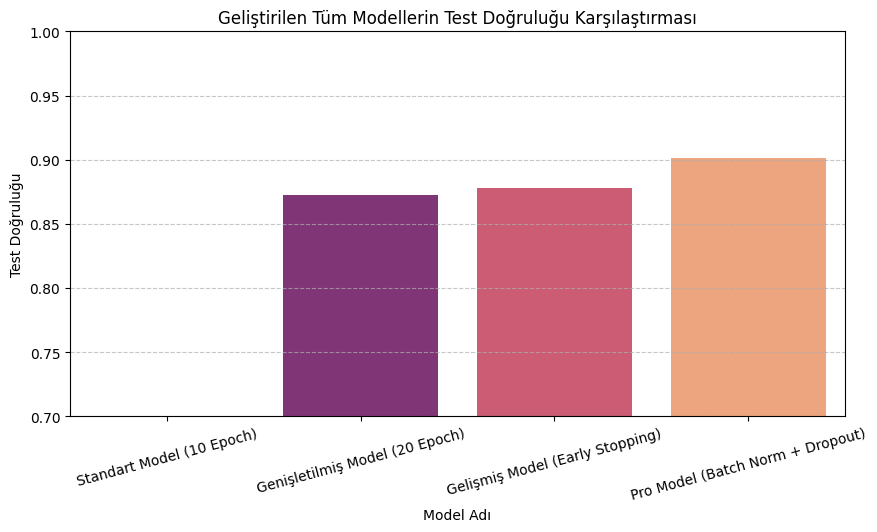

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tüm modellerin güncel test performanslarını dinamik olarak yeniden hesaplıyoruz
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
test_loss_20, test_acc_20 = model_20.evaluate(X_test, y_test, verbose=0)
test_loss_advanced, test_acc_advanced = model_advanced.evaluate(X_test, y_test, verbose=0)
test_loss_pro, test_acc_pro = model_pro.evaluate(X_test, y_test, verbose=0)

models_summary = pd.DataFrame({
    'Model Adı': ['Standart Model (10 Epoch)', 'Genişletilmiş Model (20 Epoch)', 'Gelişmiş Model (Early Stopping)', 'Pro Model (Batch Norm + Dropout)'],
    'Test Doğruluğu (Accuracy)': [test_acc, test_acc_20, test_acc_advanced, test_acc_pro]
})

# Karşılaştırma Tablosunu Göster
display(models_summary)

# Karşılaştırma Grafiği
plt.figure(figsize=(10, 5))
sns.barplot(x='Model Adı', y='Test Doğruluğu (Accuracy)', data=models_summary, palette='magma', hue='Model Adı', legend=False)
plt.ylim(0.7, 1.0)
plt.title("Geliştirilen Tüm Modellerin Test Doğruluğu Karşılaştırması")
plt.ylabel("Test Doğruluğu")
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()